In [24]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


In [25]:
print(os.listdir("/content"))


['.config', 'archive.zip', 'image_information.csv', 'flowers_dataset', 'sample_data']


In [26]:

import zipfile
import os

zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files:", zip_files)

if zip_files:
    zip_path = os.path.join("/content", zip_files[0])

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/flowers_dataset")

    print("Extraction completed!")


ZIP files: ['archive.zip']
Extraction completed!


In [27]:
class_names = [
    "daisy",
    "dandelion",
    "rose",
    "sunflower",
    "tulip"
]

root_path = "/content"

dataset_path = None

for current_root, dirs, files in os.walk(root_path):
    if set(class_names).issubset(
        {d.lower() for d in dirs}
    ):
        dataset_path = current_root
        break

if dataset_path:
    print("Dataset found:", dataset_path)
else:
    print("Five class folders were not found.")
    print("Please check the output of Cell 2.")


Dataset found: /content/flowers_dataset/flowers


In [28]:
extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

class_counts = {}

for class_name in class_names:
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    ]

    class_counts[class_name] = len(images)

display(pd.DataFrame({
    "Flower Class": list(class_counts.keys()),
    "Image Count": list(class_counts.values())
}))

print("Total images:", sum(class_counts.values()))


,Flower Class,Image Count
0,daisy,764
1,dandelion,1052
2,rose,784
3,sunflower,733
4,tulip,984


Total images: 4317


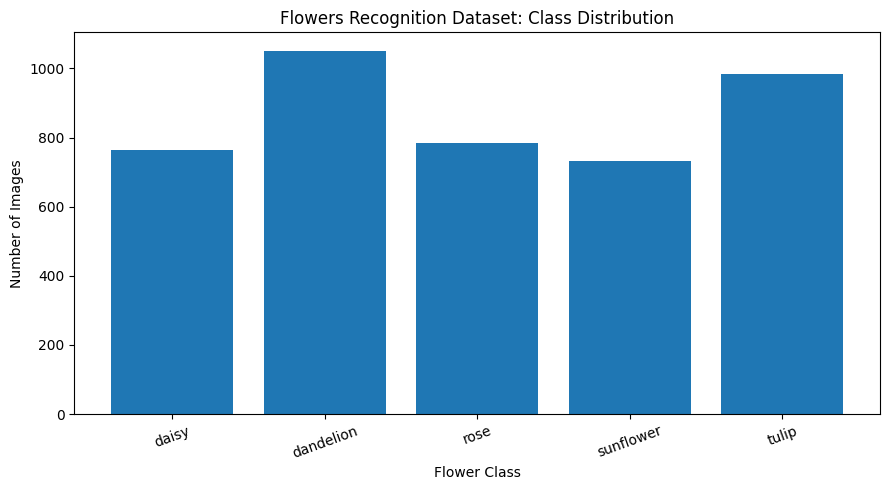

In [29]:
plt.figure(figsize=(9, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Flowers Recognition Dataset: Class Distribution")
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [30]:
counts = list(class_counts.values())

if min(counts) > 0:
    ratio = max(counts) / min(counts)

    print("Largest-to-smallest class ratio:", round(ratio, 2))

    if ratio >= 1.5:
        print("The dataset has noticeable class imbalance.")
    else:
        print("The dataset is relatively balanced.")
else:
    print("A class has zero images. Check the folder structure.")


Largest-to-smallest class ratio: 1.44
The dataset is relatively balanced.


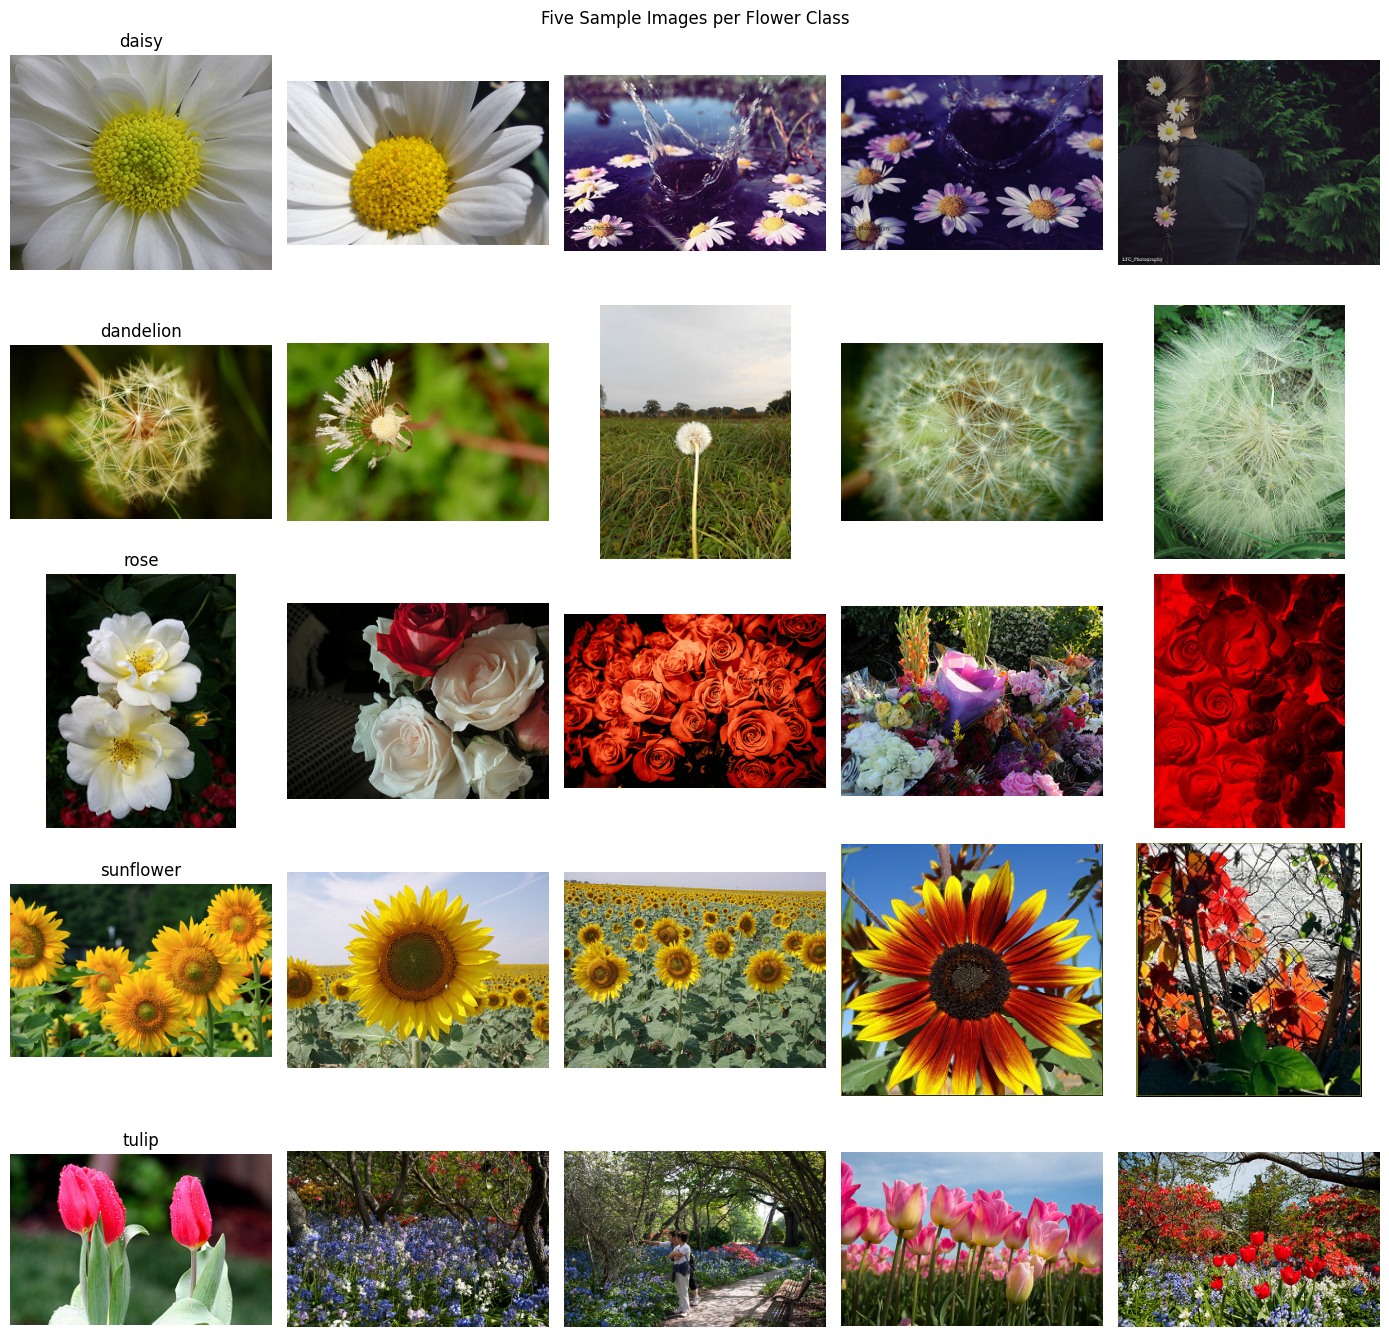

In [31]:
fig, axes = plt.subplots(5, 5, figsize=(14, 14))

for row, class_name in enumerate(class_names):
    folder = os.path.join(dataset_path, class_name)

    images = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    ])[:5]

    for col in range(5):
        ax = axes[row, col]

        if col < len(images):
            image_path = os.path.join(folder, images[col])

            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))

            if col == 0:
                ax.set_title(class_name)

        ax.axis("off")

plt.suptitle("Five Sample Images per Flower Class")
plt.tight_layout()
plt.show()


In [32]:
records = []

for class_name in class_names:
    folder = os.path.join(dataset_path, class_name)

    for filename in os.listdir(folder):
        if not filename.lower().endswith(extensions):
            continue

        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                records.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode,
                    "Format": img.format
                })

        except Exception as e:
            print("Unreadable image:", filename, e)

df = pd.DataFrame(records)

print("Total readable images:", len(df))

print("\nImage formats:")
display(df["Format"].value_counts().to_frame("Count"))

print("\nImage channels/modes:")
display(df["Mode"].value_counts().to_frame("Count"))

print("\nImage dimensions:")
display(df[["Width", "Height"]].describe())

Total readable images: 4317

Image formats:


,Count
Format,
JPEG,4317



Image channels/modes:


,Count
Mode,
RGB,4317



Image dimensions:


,Width,Height
count,4317.000000,4317.000000
mean,338.379893,253.073662
std,119.067232,61.558205
min,134.000000,80.000000
25%,240.000000,214.000000
50%,320.000000,240.000000
75%,500.000000,329.000000
max,1024.000000,442.000000


In [33]:
summary = df.groupby("Class").agg(
    Total_Images=("Filename", "count"),
    Min_Width=("Width", "min"),
    Max_Width=("Width", "max"),
    Min_Height=("Height", "min"),
    Max_Height=("Height", "max")
)

display(summary)

,Total_Images,Min_Width,Max_Width,Min_Height,Max_Height
Class,,,,,
daisy,764,134,640,134,442
dandelion,1052,134,500,98,436
rose,784,150,500,80,434
sunflower,733,152,640,134,400
tulip,984,134,1024,134,441


In [34]:
df.to_csv("/content/image_information.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [35]:
print("PREPROCESSING PLAN")
print("1. Convert images to RGB.")
print("2. Resize images to 224 x 224.")
print("3. Normalize pixel values.")
print("4. Split data into training, validation and test sets.")

print("\nDATA AUGMENTATION PLAN")
print("1. Random horizontal flip.")
print("2. Small rotations.")
print("3. Moderate zoom.")
print("4. Moderate brightness variation.")

PREPROCESSING PLAN
1. Convert images to RGB.
2. Resize images to 224 x 224.
3. Normalize pixel values.
4. Split data into training, validation and test sets.

DATA AUGMENTATION PLAN
1. Random horizontal flip.
2. Small rotations.
3. Moderate zoom.
4. Moderate brightness variation.


### A. Dataset Information

**Dataset Name:** Flowers Recognition

**Dataset Source:** [Kaggle Flowers Recognition Dataset](https://www.kaggle.com/datasets/alxmamaev/flowers-recognition)

**Problem Type:** Multiclass Image Classification

**Number of Classes:** 5

**Classes:** Daisy, Dandelion, Rose, Sunflower, and Tulip.

**Objective:** The objective is to develop a Convolutional Neural Network (CNN) model that can classify flower images into their correct categories.

**Image Information:** The total number of images, images per class, image dimensions, color channels, and file formats are inspected using Python.

**License:** Report the license shown on the Kaggle dataset page. If no license is listed, write “Not specified.”

**Domain Relevance:** Flower classification can be useful for plant identification, botanical education, and image-recognition applications.

### B. Exploratory Data Analysis (EDA) Findings

**1. Class Distribution:** A bar chart was used to examine the number of images in each flower class. The distribution helps identify whether the dataset is balanced or imbalanced.

**2. Sample Image Visualization:** Sample images from Daisy, Dandelion, Rose, Sunflower, and Tulip were displayed to observe their visual characteristics.

**3. Image Quality:** Image dimensions, color modes, and file formats were inspected to understand variations in the dataset.

**4. Class Similarity:** Some flower categories have similar colors, petal shapes, or visual patterns, which may make classification challenging.

**5. Preprocessing:** Images should be converted to RGB format, resized to a fixed size such as 224 × 224 pixels, and normalized before model training. The data should be divided into training, validation, and test sets.

**6. Data Augmentation:** Random horizontal flipping, small rotations, and moderate zooming may be applied to training images to improve model generalization.

**7. Class Imbalance:** If the class distribution is imbalanced, class weights or other suitable balancing techniques may be considered.

**Conclusion:** EDA helps identify image variations, class distribution, and potential challenges before developing the CNN model.

### C. Related Work

**Paper 1**

- **Authors:** Maria-Elena Nilsback and Andrew Zisserman
- **Year:** 2008
- **Title:** Automated Flower Classification over a Large Number of Classes
- **Dataset:** Oxford flower dataset containing 103 flower categories.
- **Model/Method:** Support Vector Machine (SVM) with multiple-kernel learning, combining color, shape, and texture features.
- **Result:** Combining multiple features achieved 72.8% classification performance, compared with 55.1% for the best single feature.
- **Link:** https://doi.org/10.1109/ICVGIP.2008.47

**Paper 2**

- **Authors:** Vincentius Praskatama, Guruh Fajar Shidik, and Amanda Prawita Ningrum
- **Year:** 2024
- **Title:** Comparative Study: Flower Classification using Deep Learning, SMOTE and Fine-Tuning
- **Dataset:** Flowers Recognition dataset containing 4,317 images across five flower classes.
- **Model/Method:** CNN, GoogLeNet, DenseNet, and MobileNet, with transfer learning, fine-tuning, and SMOTE-based balancing.
- **Result:** DenseNet achieved 93.92% test accuracy in the reported experiment.
- **Link:** https://doi.org/10.30871/jaic.v8i2.8730

**Paper 3**

- **Authors:** Agustina Mufidatuzzainiya and Muhammad Faisal
- **Year:** 2025
- **Title:** Penggunaan Teknik Transfer Learning pada Metode CNN untuk Pengenalan Tanaman Bunga
- **Dataset:** Flowers Recognition dataset containing 4,242 images across five classes.
- **Model/Method:** Basic CNN, VGG16, and EfficientNetB3 using transfer learning and data augmentation.
- **Result:** EfficientNetB3 achieved 94.00% validation accuracy in the reported experiment.
- **Link:** https://doi.org/10.14421/jiska.2025.10.2.195-206

### C. Related Work Analysis

The reviewed studies demonstrate that flower classification can be approached using traditional machine learning and deep learning techniques. Nilsback and Zisserman showed the value of combining color, shape, and texture features. The 2024 comparative study reported strong performance from DenseNet, while the 2025 study found that EfficientNetB3 with transfer learning achieved 94.00% validation accuracy.

These results suggest that CNN architectures and transfer learning are promising approaches for flower recognition. However, the reported accuracy values should not be compared directly because the datasets, data splits, and experimental settings differ.